# Предсказание следующего банковского продукта

По истории действий клиента нужно предсказать код продукта его следующего целевого клика.

- **Train** — 100 000 историй с правильными ответами в столбце `target_product`.
- **Test** — 12 359 историй без правильных ответов: их нужно предсказать.
- В train представлены **32 класса продуктов**. Коды обозначают категории, а не числовую величину.
- Метрика — **HitRate@1 (Accuracy)**: доля примеров, для которых единственный предсказанный код продукта совпал с правильным ответом.


## 1. Знакомство с данными

Сначала разберёмся, как устроены примеры и истории действий. Затем посмотрим размеры таблиц, типы столбцов и небольшой фрагмент данных без полных историй.


In [12]:
from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

# Пути при запуске из папки task3 или из корня проекта
data_dir = Path('data') if Path('data/train.parquet').exists() else Path('task3/data')
train_path = data_dir / 'train.parquet'
test_path = data_dir / 'test.parquet'
event_dictionary_path = data_dir / 'event_dictionary.parquet'


### Как устроены данные

Каждая строка — отдельный пример с историей действий клиента.

| Столбец | Что означает |
| --- | --- |
| `example_id` | Уникальный ID конкретного примера, нужен для отправки ответа на Kaggle |
| `client_id` | ID клиента, которому принадлежит история |
| `events` | Последовательность действий клиента |
| `target_product` | Код продукта следующего целевого клика — правильный ответ в train |

Один клиент может иметь несколько примеров. Поэтому `client_id` обозначает клиента, а `example_id` — конкретный пример. В test столбца `target_product` нет.

Внутри `events` хранится список событий. У каждого события есть три поля:

| Поле | Что означает |
| --- | --- |
| `timestamp` | Время события |
| `encoded_event` | Код конкретного вида действия |
| `encoded_product` | Код продукта, связанного с действием, если указан |

`encoded_event` отвечает на вопрос - "что за действие произошло?"
`encoded_product` — "с каким продуктом оно связано?"
Общую категорию действия — `event_type` (`view`, `click`, `other`, `session_boundary`) — можно получить из справочника `event_dictionary.parquet` по коду `encoded_event`. В самих событиях отдельного поля `event_type` нет.

Модель **не предсказывает `encoded_event`**. Её ответ — `target_product`, то есть код продукта следующего целевого клика.

### Пример

Ниже полностью вымышленная история одного клиента. Время, продукты и действия выбраны только для иллюстрации. Типы действий показаны словами для удобства примера.

| Время | Тип действия | Продукт |
| --- | --- | --- |
| 10:00 | `view` — просмотр | код 12 |
| 10:03 | `click` — клик | код 12 |
| 10:08 | `other` — другое действие | не указан |
| 10:12 | `view` — просмотр | код 55 |

Условный правильный ответ для этой истории: **`target_product = 55`**. Это продукт следующего целевого клика, а не код действия. Названия продуктов по этим кодам нам неизвестны.

In [13]:
# Метаданные позволяют изучить структуру без загрузки событий.
train_schema = pq.ParquetFile(train_path).schema_arrow
test_schema = pq.ParquetFile(test_path).schema_arrow
for name, path in [('train', train_path), ('test', test_path)]:
    parquet_file = pq.ParquetFile(path)
    print(f'{name}: {parquet_file.metadata.num_rows:,} строк, '
          f'{len(parquet_file.schema_arrow)} столбцов')

descriptions = {
    'example_id': 'Идентификатор примера',
    'client_id': 'Идентификатор клиента',
    'events': 'История действий клиента',
    'target_product': 'Продукт следующего клика — целевая переменная',
}
display(pd.DataFrame({
    'Столбец train': train_schema.names,
    'Тип': [str(field.type).split('<', 1)[0] for field in train_schema],
    'Описание': [descriptions.get(field.name, '') for field in train_schema],
}))
print('В test отсутствуют:', ', '.join(name for name in train_schema.names
                                      if name not in test_schema.names))


train: 100,000 строк, 4 столбцов
test: 12,359 строк, 3 столбцов


,Столбец train,Тип,Описание
0,example_id,string,Идентификатор примера
1,client_id,int32,Идентификатор клиента
2,events,list,История действий клиента
3,target_product,int32,Продукт следующего клика — целевая переменная


В test отсутствуют: target_product


## 2. Анализ целевой переменной

`target_product` — код продукта следующего целевого клика. Посмотрим, какие продукты встречаются чаще и насколько сбалансированы классы: это важно для обучения и оценки моделей.


In [ ]:
# только целевой столбец (без историй событий)
target = pq.read_table(train_path, columns=['target_product']).to_pandas()['target_product']
product_counts = target.value_counts().sort_values(ascending=False)
product_distribution = product_counts.rename_axis('Продукт').reset_index(name='Количество')
product_distribution['Доля, %'] = product_distribution['Количество'] / len(target) * 100

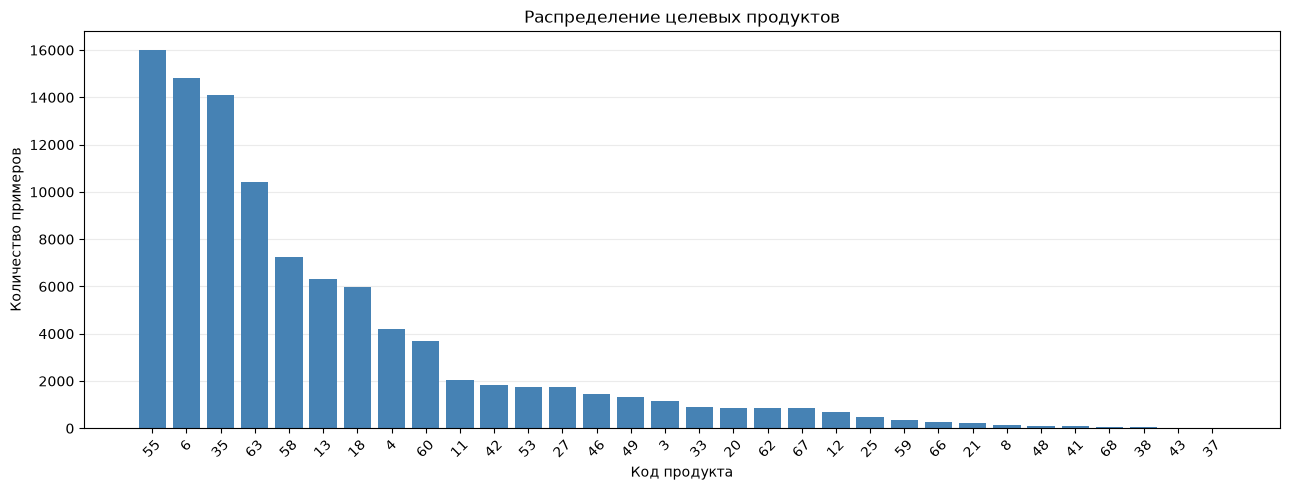

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(product_distribution['Продукт'].astype(str), product_distribution['Количество'],
       color='steelblue')
ax.set_title('Распределение целевых продуктов')
ax.set_xlabel('Код продукта')
ax.set_ylabel('Количество примеров')
ax.tick_params(axis='x', labelrotation=45)
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 3. Истории клиентов и состав событий

Сравним длины историй и состав действий в train и test. Это поможет понять, сколько информации доступно о клиенте и насколько различаются выборки.

По справочнику объединим коды действий в типы событий. Истории читаем небольшими пакетами, сохраняя только агрегаты для каждой истории.


In [16]:
from collections import Counter
import numpy as np

event_dict = pq.read_table(event_dictionary_path).to_pandas()
event_types = event_dict.set_index('encoded_event')['event_type'].to_dict()
history_stats, event_totals = {}, {}

for name, path in [('train', train_path), ('test', test_path)]:
    rows, totals = [], Counter()
    columns = ['events', 'target_product'] if name == 'train' else ['events']
    for batch in pq.ParquetFile(path).iter_batches(batch_size=32, columns=columns):
        targets = batch.column('target_product').to_pylist() if name == 'train' else [None] * len(batch)
        for history, answer in zip(batch.column('events').to_pylist(), targets):
            events = history or []
            kinds = [event_types.get(e['encoded_event'], 'unknown') if e else 'unknown' for e in events]
            products = [e['encoded_product'] if e else None for e in events]
            known_products = [p for p in products if p is not None]
            clicked_products = {p for p, kind in zip(products, kinds) if kind == 'click' and p is not None}
            counts = Counter(kinds)
            totals.update(counts)
            row = {
                'history_length': len(events), 'n_click': counts['click'],
                'n_view': counts['view'], 'n_unique_products': len(set(known_products)),
                'known_product_rate': len(known_products) / len(events) if events else np.nan,
            }
            if name == 'train':
                last_product = known_products[-1] if known_products else None
                row.update({
                    'target_product': answer,
                    'target_seen': answer in known_products if answer is not None else np.nan,
                    'target_clicked': answer in clicked_products if answer is not None else np.nan,
                    'target_recent100': answer in products[-100:] if answer is not None else np.nan,
                    'target_is_last_known': answer == last_product if answer is not None else np.nan,
                })
            rows.append(row)
    history_stats[name] = pd.DataFrame(rows).astype({
        'history_length': 'uint32', 'n_click': 'uint32', 'n_view': 'uint32',
        'n_unique_products': 'uint32', 'known_product_rate': 'float32',
    })
    event_totals[name] = totals
    del rows


### Длины историй и доступная информация

Сравним длины историй, число кликов и разнообразие продуктов. На графике показана доля историй не длиннее заданного числа событий — так выборки разного размера удобно сопоставлять.


train


,count,mean,std,min,50%,90%,99%,max
history_length,100000.0,736.985,597.841,20.0,552.000,1845.00,2000.000,2000.000
n_click,100000.0,30.649,34.807,0.0,19.000,75.00,158.000,1208.000
n_view,100000.0,317.994,253.678,0.0,248.000,704.00,1044.000,1930.000
n_unique_products,100000.0,10.118,3.703,0.0,10.000,15.00,19.000,31.000
known_product_rate,100000.0,0.226,0.107,0.0,0.211,0.37,0.526,0.913


Историй с 2000 событиями: 8.40%
test


,count,mean,std,min,50%,90%,99%,max
history_length,12359.0,1056.976,649.937,21.0,944.000,2000.00,2000.00,2000.00
n_click,12359.0,44.510,45.510,0.0,30.000,104.00,202.00,575.00
n_view,12359.0,482.138,300.269,4.0,435.000,899.00,1241.42,1680.00
n_unique_products,12359.0,11.845,3.743,0.0,12.000,16.00,20.00,28.00
known_product_rate,12359.0,0.243,0.098,0.0,0.236,0.37,0.52,0.81


Историй с 2000 событиями: 19.92%


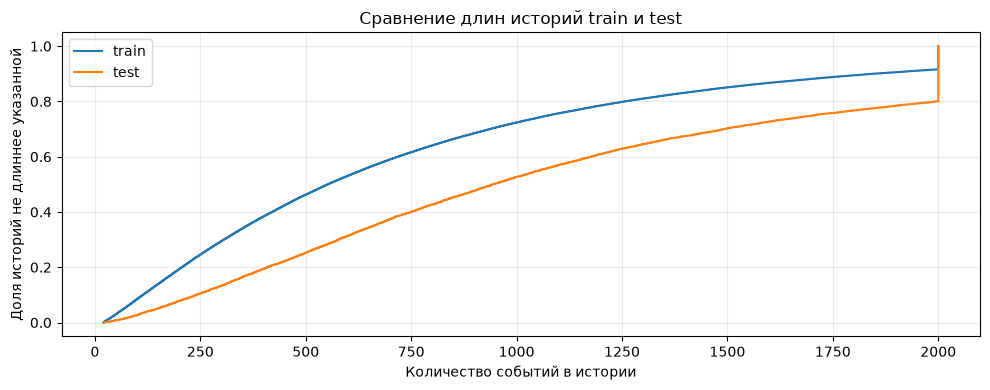

In [17]:
for name, frame in history_stats.items():
    print(name)
    display(frame[['history_length', 'n_click', 'n_view', 'n_unique_products',
                   'known_product_rate']].describe(percentiles=[.5, .9, .99]).round(3).T)
    print(f"Историй с 2000 событиями: {frame['history_length'].eq(2000).mean():.2%}")

fig, ax = plt.subplots(figsize=(10, 4))
for name, frame in history_stats.items():
    lengths = np.sort(frame['history_length'].to_numpy())
    ax.plot(lengths, np.arange(1, len(lengths) + 1) / len(lengths), label=name)
ax.set(title='Сравнение длин историй train и test',
       xlabel='Количество событий в истории', ylabel='Доля историй не длиннее указанной')
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


### Просмотры, клики и другие действия

Сравним доли типов среди всех событий train и test. Длинные истории вносят больший вклад в эти доли.


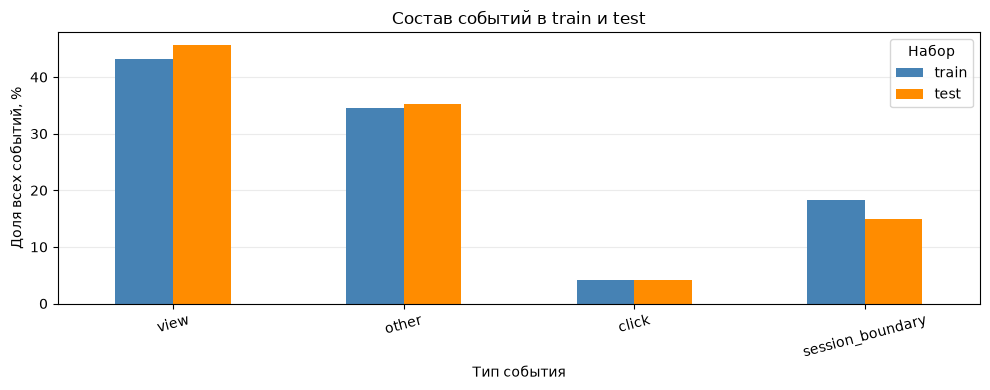

In [18]:
type_counts = pd.DataFrame(event_totals).fillna(0).astype('int64')
type_shares = type_counts.div(type_counts.sum(axis=0), axis=1) * 100
ax = type_shares.plot.bar(figsize=(10, 4), rot=15, color=['steelblue', 'darkorange'])
ax.set(title='Состав событий в train и test', xlabel='Тип события', ylabel='Доля всех событий, %')
ax.legend(title='Набор')
ax.grid(axis='y', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


## 4. Связь истории с целевым продуктом

Проверим, встречался ли целевой продукт в истории, среди кликов и в последних 100 событиях. Отдельно посмотрим совпадение с последним известным продуктом.

Первые три доли показывают покрытие возможных ответов, а не Accuracy: история может содержать несколько продуктов. Последний показатель соответствует выбору одного продукта. Пропуски цели исключаем, неизвестные продукты не считаем отдельной категорией. Последние события определяем по исходному хронологическому порядку.


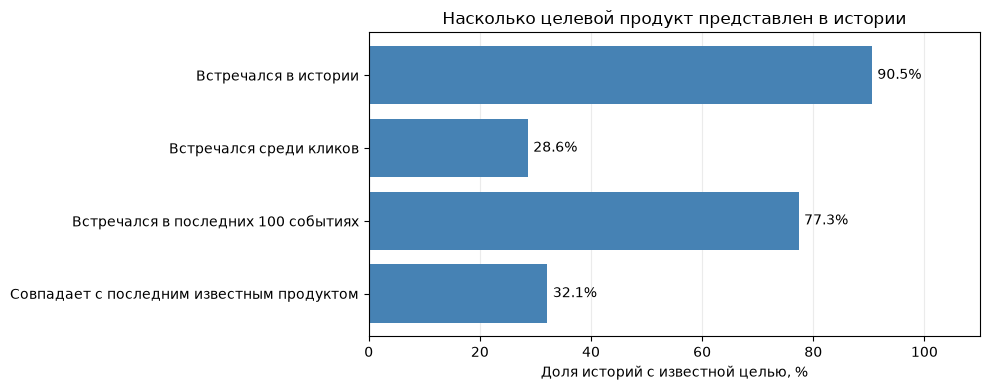

Десять самых частых целевых продуктов; показатели совпадения в процентах:


,Количество,Встречался_в_истории,Встречался_среди_кликов,Совпадает_с_последним
Код целевого продукта,,,,
55,16008,83.71,37.73,4.90
6,14830,97.01,24.77,44.46
35,14080,99.35,56.04,57.96
63,10438,94.24,19.89,22.45
58,7249,95.05,28.61,32.39
13,6300,97.81,21.86,43.63
18,5964,93.95,21.38,36.94
4,4193,98.21,28.86,35.99
60,3687,75.78,5.51,9.47


In [19]:
train_history = history_stats['train'].dropna(subset=['target_product'])
coverage_columns = {
    'target_seen': 'Встречался в истории',
    'target_clicked': 'Встречался среди кликов',
    'target_recent100': 'Встречался в последних 100 событиях',
    'target_is_last_known': 'Совпадает с последним известным продуктом',
}
coverage = train_history[list(coverage_columns)].mean().mul(100)
coverage.index = coverage.index.map(coverage_columns)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(coverage.index, coverage.values, color='steelblue')
ax.bar_label(bars, fmt='%.1f%%', padding=4)
ax.set(title='Насколько целевой продукт представлен в истории',
       xlabel='Доля историй с известной целью, %', xlim=(0, 110))
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Проверим, не скрывает ли средняя доля различия между популярными продуктами.
by_product = train_history.groupby('target_product').agg(
    Количество=('target_seen', 'size'),
    Встречался_в_истории=('target_seen', 'mean'),
    Встречался_среди_кликов=('target_clicked', 'mean'),
    Совпадает_с_последним=('target_is_last_known', 'mean'),
).sort_values('Количество', ascending=False).head(10)
by_product.iloc[:, 1:] = by_product.iloc[:, 1:] * 100
print('Десять самых частых целевых продуктов; показатели совпадения в процентах:')
display(by_product.round(2).rename_axis('Код целевого продукта'))


## Выводы по EDA

- Классы несбалансированы: пять самых частых продуктов составляют около **62,6%** train. Это важно учитывать при оценке Accuracy.
- Истории test длиннее: медиана **944** события против **552** в train. Доля историй длиной 2000 событий — **19,92%** против **8,40%**. Поэтому абсолютные количества действий стоит дополнять долями.
- Среди событий преобладают просмотры; клики составляют около **4%** в обеих выборках. В признаках полезно разделять типы взаимодействий.
- Целевой продукт уже встречался в **90,53%** историй, но среди кликов — лишь в **28,61%**. Повторный интерес заметен не только через клики: стоит учитывать и другие взаимодействия с продуктом.
- Даже последние **100 событий** содержат целевой продукт в **77,34%** случаев. Это поддерживает идею признаков недавнего интереса, хотя ограничение истории этим окном теряет часть покрытия.
- Последний известный продукт совпадает с целью в **32,13%** случаев. Связь различается по классам: для продукта `35` совпадение — **57,96%**, для `55` — **4,90%**. Один признак последнего продукта не заменяет частоты и состав всей истории.

Для baseline подготовим длину истории, количества и доли действий, частоты взаимодействий с продуктами и признаки последних событий. Покрытие продуктов в истории не равно качеству модели; качество проверим на отдельной валидации.
